# 08 · WavLM-Large + MLP MOS regressor
**GPU runtime** (T4 is fine). Run after `07_MOS_Dataset_v2`.

- Uses the grouped split from `mos_metadata.csv`; val/test are unaugmented.
- Early stopping on validation MSE (patience 10, min Δ 0.001); the best-validation checkpoint is restored, tested and exported.
- Seeded; results over 5 training seeds, reported as mean ± SD.
- Mean and ridge-regression baselines, group-bootstrap 95% CIs, errors per MOS bin and per source.
- The final model is trained **without** augmentation (it gave no benefit and made the model more sensitive to
  pitch-shift artefacts, see notebook 09). A model trained with augmentation is kept as an ablation at the end.

Embeddings are cached on Drive (one file per clip), so after a disconnect just re-run: finished clips are skipped.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os, copy, random, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import librosa, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from transformers import AutoFeatureExtractor, AutoModel
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

OUT = "/content/drive/MyDrive/szakdolgozat/v2"
RES = f"{OUT}/results"
AUDIO = "/content/mos_audio"
EMB_DIR = f"{OUT}/emb"
for d in [RES, EMB_DIR, f"{OUT}/models"]:
    os.makedirs(d, exist_ok=True)

SR = 16000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WAVLM_MODEL = "microsoft/wavlm-large"
LR = 5e-5
BATCH_SIZE = 8
MAX_EPOCHS = 100
PATIENCE, MIN_DELTA = 10, 1e-3
HIDDEN_DIM = 512
SEEDS = [0, 1, 2, 3, 4]      # SEEDS[0] is the model exported to the webapp
TRAIN = "train_noaug"        # final training set: original train clips only ("train" = incl. augmented)

In [3]:
df = pd.read_csv(f"{OUT}/mos_metadata.csv")
if not os.path.exists(AUDIO):
    with zipfile.ZipFile(f"{OUT}/mos_audio.zip") as z:
        z.extractall(AUDIO)
pd.crosstab(df.split, df.source, margins=True)

source,mast,singmos,All
split,,,
test,95,1099,1194
train,1059,3688,4747
val,94,1222,1316
All,1248,6009,7257


## WavLM embeddings
WavLM is **frozen**. Each clip is fed whole (no padding, no truncation); the last hidden layer
(T × 1024) is **mean-pooled over time** into one 1024-d vector. Same code path as `utils/predict_mos.py`.

In [4]:
extractor = AutoFeatureExtractor.from_pretrained(WAVLM_MODEL)
wavlm = AutoModel.from_pretrained(WAVLM_MODEL).to(DEVICE).eval()

# Guard: some transformers versions silently re-initialise WavLM's positional conv weights
# (checkpoint stores them as weight_g/weight_v). Two loads would then give different embeddings.
_w2 = AutoModel.from_pretrained(WAVLM_MODEL).to(DEVICE).eval()
with torch.no_grad():
    _x = torch.randn(1, SR, device=DEVICE)
    assert torch.allclose(wavlm(_x).last_hidden_state, _w2(_x).last_hidden_state, atol=1e-4), "WavLM weights not fully loaded"
del _w2
import transformers; print("transformers", transformers.__version__, "- pin this version in streamlit-webapp/requirements.txt")

@torch.no_grad()
def embed(wave):
    inputs = extractor(wave, sampling_rate=SR, return_tensors="pt").to(DEVICE)
    return wavlm(**inputs).last_hidden_state[0].mean(0).cpu().numpy()

def load_audio(path):
    return librosa.load(path, sr=SR, mono=True)[0]

CACHE = f"{OUT}/embeddings_all.npz"
cached = np.load(CACHE, allow_pickle=True) if os.path.exists(CACHE) else None
if cached is not None and list(cached["wav"]) == df.wav.tolist():
    X = cached["X"]
else:
    for w in tqdm(df.wav, desc="embedding"):
        p = f"{EMB_DIR}/{w[:-4]}.npy"
        if not os.path.exists(p):
            np.save(p, embed(load_audio(f"{AUDIO}/{w}")))
    X = np.stack([np.load(f"{EMB_DIR}/{w[:-4]}.npy") for w in tqdm(df.wav, desc="loading")])
    np.savez(CACHE, X=X, wav=df.wav.values)
X.shape

preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

transformers 5.20.1 - pin this version in streamlit-webapp/requirements.txt


(7257, 1024)

In [5]:
y = df.mos.values.astype(np.float32)
idx = {s: (df.split == s).values for s in ["train", "val", "test"]}
idx["train_noaug"] = idx["train"] & ~df.is_aug.values
Xt = {s: torch.tensor(X[m], dtype=torch.float32) for s, m in idx.items()}
yt = {s: torch.tensor(y[m]) for s, m in idx.items()}
ytr, yva, yte = y[idx[TRAIN]], y[idx["val"]], y[idx["test"]]
test = df[idx["test"]].reset_index(drop=True)
print({s: int(m.sum()) for s, m in idx.items()})

{'train': 4747, 'val': 1316, 'test': 1194, 'train_noaug': 4350}


## Final data used: train without augmentation, val/test natural

source  mast  singmos   All
split                      
train    780     3570  4350
val       94     1222  1316
test      95     1099  1194
All      969     5891  6860


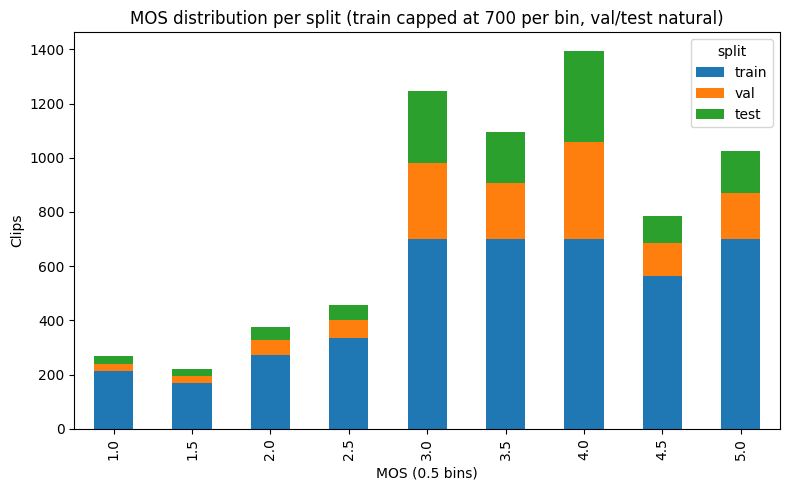

In [6]:
used = df[idx[TRAIN] | idx["val"] | idx["test"]]
t1 = pd.crosstab(used.split, used.source, margins=True).loc[["train", "val", "test", "All"]]
t1.to_csv(f"{RES}/table1_mos_splits_final.csv"); print(t1)
ct = pd.crosstab(used.mos_bin, used.split)[["train", "val", "test"]]
ct.to_csv(f"{RES}/mos_bins_by_split_final.csv")
ct.plot.bar(stacked=True, figsize=(8, 5), xlabel="MOS (0.5 bins)", ylabel="Clips",
            title="MOS distribution per split (train capped at 700 per bin, val/test natural)")
plt.tight_layout(); plt.savefig(f"{RES}/fig1_mos_distribution_final.png", dpi=200); plt.show()

## Model and training
MLP head: 1024 → 512 (ReLU, dropout 0.2) → 256 (ReLU, dropout 0.1) → 1. No input scaling, raw MOS target.
AdamW, MSE loss, batch 8.

In [7]:
class RegressorMLP(nn.Module):
    def __init__(self, in_dim, hidden_dim=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(hidden_dim//2, 1)
        )

    def forward(self, x):
        x = self.net(x).squeeze(-1)
        return x

@torch.no_grad()
def predict(model, X):
    model.eval()
    return model(X.to(DEVICE)).cpu().numpy()

def train_mlp(seed, train=TRAIN):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = RegressorMLP(1024, HIDDEN_DIM).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(Xt[train], yt[train]), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    best, best_epoch, best_state, wait, hist = np.inf, 0, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for xb, yb in loader:
            loss = loss_fn(model(xb.to(DEVICE)), yb.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        val_mse = mean_squared_error(yva, predict(model, Xt["val"]))
        hist.append((epoch, np.mean(losses), val_mse))
        if val_mse < best - MIN_DELTA:
            best, best_epoch, best_state, wait = val_mse, epoch, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, best_epoch, pd.DataFrame(hist, columns=["epoch", "train_mse", "val_mse"])

def rmse(a, b):
    return mean_squared_error(a, b) ** 0.5

def metrics(t, p):
    return {"r2": r2_score(t, p), "rmse": rmse(t, p), "mse": mean_squared_error(t, p),
            "mae": mean_absolute_error(t, p), "pearson": pearsonr(t, p)[0], "spearman": spearmanr(t, p)[0]}

def group_bootstrap(t, p, groups, fn, n=1000, seed=0):
    """95% CI resampling whole groups (song segment / melody), not single clips."""
    rng = np.random.default_rng(seed)
    members = list(pd.Series(np.arange(len(t))).groupby(np.asarray(groups)).apply(np.array))
    stats = [fn(t[i], p[i]) for i in
             (np.concatenate([members[j] for j in rng.integers(0, len(members), len(members))]) for _ in range(n))]
    return np.percentile(stats, [2.5, 97.5])

In [8]:
runs, test_preds = [], {}
for seed in SEEDS:
    model, best_epoch, hist = train_mlp(seed)
    p = predict(model, Xt["test"])
    test_preds[seed] = p
    runs.append({"seed": seed, "best_epoch": best_epoch, "stopped_epoch": len(hist),
                 **{f"val_{k}": v for k, v in metrics(yva, predict(model, Xt["val"])).items()},
                 **{f"test_{k}": v for k, v in metrics(yte, p).items()}})
    print(runs[-1])
    if seed == SEEDS[0]:
        torch.save(model.state_dict(), f"{OUT}/models/wavlm_mlp_mos_regressor.pt")
        hist.to_csv(f"{RES}/mos_loss_history_seed{seed}.csv", index=False)
        hist0, best0 = hist, best_epoch

runs = pd.DataFrame(runs)
runs.to_csv(f"{RES}/mos_seed_runs.csv", index=False)
summary = runs.drop(columns="seed").agg(["mean", "std"]).T.round(4)
summary.to_csv(f"{RES}/mos_seed_summary.csv"); summary

{'seed': 0, 'best_epoch': 12, 'stopped_epoch': 22, 'val_r2': 0.4322667717933655, 'val_rmse': 0.6948537706322087, 'val_mse': 0.4828217625617981, 'val_mae': 0.5479667782783508, 'val_pearson': np.float32(0.66140944), 'val_spearman': np.float64(0.601115903984441), 'test_r2': 0.3984348177909851, 'test_rmse': 0.7170065591317926, 'test_mse': 0.5140984058380127, 'test_mae': 0.5603868365287781, 'test_pearson': np.float32(0.63829565), 'test_spearman': np.float64(0.5695795862165525)}
{'seed': 1, 'best_epoch': 17, 'stopped_epoch': 27, 'val_r2': 0.43097537755966187, 'val_rmse': 0.6956435926134209, 'val_mse': 0.48392000794410706, 'val_mae': 0.5488554239273071, 'val_pearson': np.float32(0.662467), 'val_spearman': np.float64(0.6070764484393744), 'test_r2': 0.3984874486923218, 'test_rmse': 0.7169751769281886, 'test_mse': 0.5140534043312073, 'test_mae': 0.5573686361312866, 'test_pearson': np.float32(0.643523), 'test_spearman': np.float64(0.5796171458027589)}
{'seed': 2, 'best_epoch': 11, 'stopped_epoch'

,mean,std
best_epoch,12.6000,2.5100
stopped_epoch,22.6000,2.5100
val_r2,0.4310,0.0042
val_rmse,0.6956,0.0026
val_mse,0.4839,0.0036
val_mae,0.5492,0.0032
val_pearson,0.6600,0.0036
val_spearman,0.6006,0.0052
test_r2,0.3969,0.0015
test_rmse,0.7179,0.0009


## Loss curve of the exported model
The dashed line is the restored/tested checkpoint; training stopped `PATIENCE` epochs later.

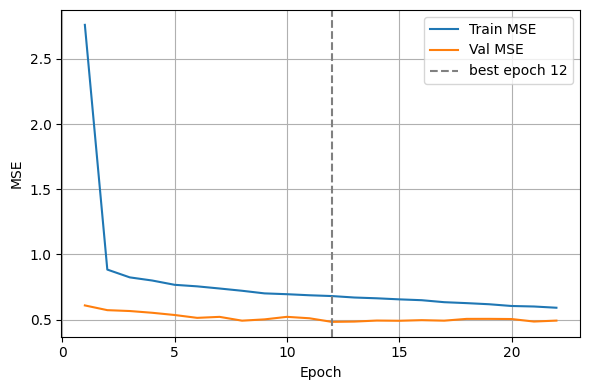

best epoch 12, stopped after epoch 22


In [9]:
plt.figure(figsize=(6, 4))
plt.plot(hist0.epoch, hist0.train_mse, label="Train MSE")
plt.plot(hist0.epoch, hist0.val_mse, label="Val MSE")
plt.axvline(best0, ls="--", c="gray", label=f"best epoch {best0}")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(f"{RES}/fig8_mos_loss.png", dpi=200); plt.show()
print(f"best epoch {best0}, stopped after epoch {len(hist0)}")

## Baselines with 95% group-bootstrap CIs (test set)

In [10]:
alphas = [0.1, 1, 10, 100, 1000, 10000]
ridge_fit = lambda a: make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X[idx[TRAIN]], ytr)
best_alpha = min(alphas, key=lambda a: mean_squared_error(yva, ridge_fit(a).predict(X[idx["val"]])))

candidates = {
    "Mean of train MOS": np.full(len(yte), ytr.mean()),
    f"Ridge on WavLM embeddings (alpha={best_alpha})": ridge_fit(best_alpha).predict(X[idx["test"]]),
    "WavLM + MLP (seed 0, exported)": test_preds[SEEDS[0]],
}
rows = []
for name, p in candidates.items():
    m = metrics(yte, p)
    r2_ci = group_bootstrap(yte, p, test.group, r2_score)
    rmse_ci = group_bootstrap(yte, p, test.group, rmse)
    rows.append({"model": name, **{k: round(v, 3) for k, v in m.items()},
                 "r2_95ci": f"[{r2_ci[0]:.3f}, {r2_ci[1]:.3f}]", "rmse_95ci": f"[{rmse_ci[0]:.3f}, {rmse_ci[1]:.3f}]"})
baselines = pd.DataFrame(rows)
baselines.to_csv(f"{RES}/table3_mos_baselines.csv", index=False); baselines

/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.41501e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/tmp/ipykernel_3095/1257609364.py:56: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "mae": mean_absolute_error(t, p), "pearson": pearsonr(t, p)[0], "spearman": spearmanr(t, p)[0]}


,model,r2,rmse,mse,mae,pearson,spearman,r2_95ci,rmse_95ci
0,Mean of train MOS,-0.012,0.930,0.864,0.737,NaN,NaN,"[-0.069, -0.000]","[0.823, 1.032]"
1,Ridge on WavLM embeddings (alpha=1000),0.403,0.714,0.510,0.561,0.636,0.577,"[0.312, 0.475]","[0.643, 0.786]"
2,"WavLM + MLP (seed 0, exported)",0.398,0.717,0.514,0.560,0.638,0.570,"[0.279, 0.489]","[0.647, 0.792]"


## Errors per MOS bin and per source (seed 0 model)
`bias` = mean(pred − true). Positive at low bins / negative at high bins = regression toward the mean.

In [11]:
test["pred"] = test_preds[SEEDS[0]]
for s in SEEDS:
    test[f"pred_seed{s}"] = test_preds[s]
test["err"] = test.pred - test.mos

def err_table(by):
    g = test.assign(abs_err=test.err.abs(), sq_err=test.err ** 2).groupby(by)
    t = g.agg(n=("err", "size"), mae=("abs_err", "mean"), mse=("sq_err", "mean"), bias=("err", "mean"))
    t["rmse"] = np.sqrt(t.pop("mse"))
    return t.round(3)

by_bin = err_table("mos_bin"); by_bin.to_csv(f"{RES}/mos_errors_by_bin.csv"); print(by_bin)
by_src = err_table(["source", "subtype"]); by_src.to_csv(f"{RES}/mos_errors_by_source.csv"); print(by_src)

# Within-source fit: does the model rank clips correctly inside each source,
# or does it mostly separate MAST (low) from SingMOS (high)?
within = pd.DataFrame({src: metrics(g.mos.values, g.pred.values) for src, g in test.groupby("source")}).T.round(3)
within["n"] = test.source.value_counts()
within.to_csv(f"{RES}/mos_metrics_by_source.csv"); within

           n    mae   bias   rmse
mos_bin                          
1.0       29  0.749  0.686  0.895
1.5       27  1.001  0.941  1.135
2.0       46  0.999  0.921  1.071
2.5       52  0.768  0.685  0.889
3.0      266  0.485  0.359  0.616
3.5      186  0.389  0.078  0.479
4.0      335  0.385 -0.161  0.510
4.5      101  0.698 -0.659  0.875
5.0      152  0.878 -0.878  1.005
                   n    mae   bias   rmse
source  subtype                          
mast    human     95  1.122  0.018  1.295
singmos gt        82  0.586 -0.322  0.687
        svc      192  0.573 -0.083  0.700
        svr      350  0.501 -0.021  0.623
        svs      475  0.482  0.057  0.626


,r2,rmse,mse,mae,pearson,spearman,n
mast,0.196,1.295,1.677,1.122,0.447,0.525,95
singmos,0.337,0.643,0.414,0.512,0.597,0.556,1099


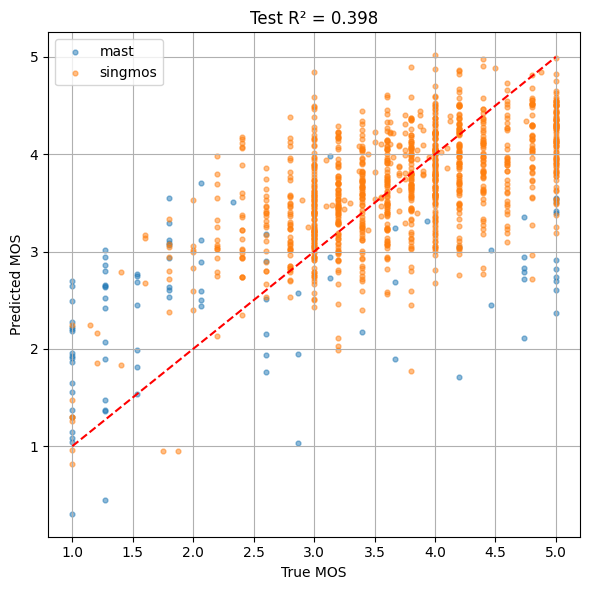

In [12]:
plt.figure(figsize=(6, 6))
for src, g in test.groupby("source"):
    plt.scatter(g.mos, g.pred, alpha=0.5, s=12, label=src)
plt.plot([1, 5], [1, 5], "r--")
plt.xlabel("True MOS"); plt.ylabel("Predicted MOS"); plt.legend(); plt.grid(True)
plt.title(f"Test R² = {r2_score(test.mos, test.pred):.3f}")
plt.tight_layout(); plt.savefig(f"{RES}/fig7_mos_scatter.png", dpi=200); plt.show()

## Ablation: the same model trained WITH the augmented clips
The augmented variant adds pitch-shifted/time-stretched copies (±1 semitone, 0.98–1.02) of low-MOS training clips.
Same seeds and settings, trained on train + augmented clips. Notebook 09 compares both models.

In [13]:
aug_runs, aug_preds = [], {}
for seed in SEEDS:
    model, best_epoch, hist = train_mlp(seed, "train")
    p = predict(model, Xt["test"])
    aug_preds[seed] = p
    aug_runs.append({"seed": seed, "best_epoch": best_epoch, "stopped_epoch": len(hist),
                     **{f"val_{k}": v for k, v in metrics(yva, predict(model, Xt["val"])).items()},
                     **{f"test_{k}": v for k, v in metrics(yte, p).items()}})
    if seed == SEEDS[0]:
        torch.save(model.state_dict(), f"{OUT}/models/wavlm_mlp_mos_regressor_aug.pt")
aug_runs = pd.DataFrame(aug_runs)
aug_runs.to_csv(f"{RES}/mos_seed_runs_aug.csv", index=False)
test["pred_aug"] = aug_preds[SEEDS[0]]

aug_cmp = pd.concat({"without augmentation (final)": runs.drop(columns="seed").agg(["mean", "std"]).T,
                     "with augmentation": aug_runs.drop(columns="seed").agg(["mean", "std"]).T}, axis=1).round(4)
aug_cmp.to_csv(f"{RES}/mos_augmentation_ablation.csv"); print(aug_cmp)

per_src = pd.DataFrame({(name, src): metrics(g.mos.values, g[col].values)
                        for name, col in [("without aug (final)", "pred"), ("with aug", "pred_aug")]
                        for src, g in test.groupby("source")}).T.round(3)
per_src.to_csv(f"{RES}/mos_augmentation_ablation_by_source.csv"); per_src

              without augmentation (final)         with augmentation        
                                      mean     std              mean     std
best_epoch                         12.6000  2.5100           11.0000  2.3452
stopped_epoch                      22.6000  2.5100           21.0000  2.3452
val_r2                              0.4310  0.0042            0.4381  0.0042
val_rmse                            0.6956  0.0026            0.6913  0.0026
val_mse                             0.4839  0.0036            0.4779  0.0036
val_mae                             0.5492  0.0032            0.5465  0.0043
val_pearson                         0.6600  0.0036            0.6642  0.0035
val_spearman                        0.6006  0.0052            0.6009  0.0051
test_r2                             0.3969  0.0015            0.3930  0.0069
test_rmse                           0.7179  0.0009            0.7203  0.0041
test_mse                            0.5155  0.0013            0.5188  0.0059

r2   rmse    mse    mae  pearson  spearman
without aug (final) mast     0.196  1.295  1.677  1.122    0.447     0.525
                    singmos  0.337  0.643  0.414  0.512    0.597     0.556
with aug            mast     0.181  1.307  1.708  1.115    0.431     0.498
                    singmos  0.342  0.641  0.410  0.508    0.602     0.563

In [14]:
test.drop(columns="err").to_csv(f"{OUT}/mos_test_preds.csv", index=False)
print("saved", f"{OUT}/mos_test_preds.csv", "and both models in", f"{OUT}/models")

saved /content/drive/MyDrive/szakdolgozat/v2/mos_test_preds.csv and both models in /content/drive/MyDrive/szakdolgozat/v2/models
